# Univariate Time Series Models II
**HS 821 · Lectures 6–8 · Topics in Time Series Econometrics**

**Sunil Paul**

August 2026 · R 4.6

Lecture 5 built the probabilistic vocabulary of stationary processes — the mean, autocovariance and autocorrelation functions, white noise, the Wold decomposition, and the moving-average (MA) family whose ACF *cuts off* after the order of the process.

This lecture develops the two workhorse families that dominate applied univariate modelling: the **autoregressive (AR)** process, whose ACF *decays* rather than cuts off, and the mixed **autoregressive–moving-average (ARMA)** process. The unifying tool is the **lag polynomial and its roots**: stationarity, persistence, cycles, and invertibility can all be read off from where those roots sit relative to the unit circle.


*Estimation and statistical inference (fitting $\phi,\theta,\sigma^2$; standard errors; information criteria; diagnostic tests) are deferred to the next lecture. Here the parameters are known and every ACF, PACF, and impulse response is a **population** quantity, except where a figure is explicitly labelled as a **sample** correlogram.*

## Setup

As in Lecture 5 we first define a small set of plotting helpers so the later cells stay short. All theoretical quantities use base-R `stats` routines:

- `ARMAacf()` — population ACF and PACF of an ARMA process;
- `ARMAtoMA()` — the Wold / MA($\infty$) coefficients $\psi_j$ (the impulse response);
- `arima.sim()` — one simulated realization;
- `polyroot()` / `eigen()` — roots of the lag polynomial and eigenvalues of the companion matrix.

In [1]:
# ------------------------------------------------------------------
# Setup: plotting helpers (self-contained; theme_classic throughout)
# ------------------------------------------------------------------
suppressPackageStartupMessages({
  library(ggplot2)
  library(gridExtra)
})

# Time-series line plot; optional dashed reference line at the mean.
ts_plot <- function(x, mu = NULL, title = NULL) {
  time_idx <- if (is.ts(x)) as.numeric(time(x)) else seq_along(x)
  df <- data.frame(time = time_idx, value = as.numeric(x))
  p <- ggplot(df, aes(time, value)) +
    theme_classic() + geom_line() + labs(x = "Time", y = NULL, title = title)
  if (!is.null(mu)) p <- p + geom_hline(yintercept = mu, linetype = "dashed")
  p
}

# Theoretical ACF of an ARMA process, lags 1..L (lag 0 dropped).
acf_plot <- function(ar = numeric(0), ma = numeric(0), L = 15, title = NULL) {
  rho <- ARMAacf(ar = ar, ma = ma, lag.max = L)[-1]
  df  <- data.frame(lag = seq_len(L), acf = as.numeric(rho))
  ggplot(df, aes(lag, acf)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = lag, y = 0, yend = acf), linewidth = 1) +
    geom_point(size = 2) +
    scale_x_continuous(breaks = seq(0, L, by = 3)) +
    labs(x = "Lag", y = "ACF", title = title)
}

# Theoretical PACF of an ARMA process, lags 1..L.
pacf_plot <- function(ar = numeric(0), ma = numeric(0), L = 15, title = NULL) {
  pac <- ARMAacf(ar = ar, ma = ma, lag.max = L, pacf = TRUE)
  df  <- data.frame(lag = seq_len(L), pacf = as.numeric(pac))
  ggplot(df, aes(lag, pacf)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = lag, y = 0, yend = pacf), linewidth = 1) +
    geom_point(size = 2) +
    scale_x_continuous(breaks = seq(0, L, by = 3)) +
    labs(x = "Lag", y = "PACF", title = title)
}

# Theoretical impulse response = Wold coefficients psi_0=1, psi_1, psi_2, ...
irf_plot <- function(ar = numeric(0), ma = numeric(0), h = 20, title = NULL) {
  psi <- c(1, ARMAtoMA(ar = ar, ma = ma, lag.max = h))
  df  <- data.frame(horizon = 0:h, response = psi)
  ggplot(df, aes(horizon, response)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = horizon, y = 0, yend = response)) +
    geom_point() +
    scale_x_continuous(breaks = seq(0, h, by = 4)) +
    labs(x = "Horizon after a unit innovation", y = "Response", title = title)
}

# Sample ACF / PACF with approximate +/- 2/sqrt(T) bands.
sample_acf_plot <- function(x, L = 20, title = NULL) {
  a  <- acf(x, plot = FALSE, lag.max = L)
  df <- data.frame(lag = as.numeric(a$lag)[-1], acf = as.numeric(a$acf)[-1])
  b  <- 2 / sqrt(length(x))
  ggplot(df, aes(lag, acf)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = lag, y = 0, yend = acf), linewidth = 1) +
    geom_point(size = 2) +
    geom_hline(yintercept = c(b, -b), linetype = "dashed", colour = "red") +
    scale_x_continuous(breaks = seq(0, L, by = 3)) +
    labs(x = "Lag", y = "Sample ACF", title = title)
}

sample_pacf_plot <- function(x, L = 20, title = NULL) {
  a  <- pacf(x, plot = FALSE, lag.max = L)
  df <- data.frame(lag = as.numeric(a$lag), acf = as.numeric(a$acf))
  b  <- 2 / sqrt(length(x))
  ggplot(df, aes(lag, acf)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = lag, y = 0, yend = acf), linewidth = 1) +
    geom_point(size = 2) +
    geom_hline(yintercept = c(b, -b), linetype = "dashed", colour = "red") +
    scale_x_continuous(breaks = seq(0, L, by = 3)) +
    labs(x = "Lag", y = "Sample PACF", title = title)
}

# Roots of a lag polynomial on the complex plane, with the unit circle.
roots_plot <- function(roots, title = NULL) {
  theta <- seq(0, 2 * pi, length.out = 400)
  circ  <- data.frame(x = cos(theta), y = sin(theta))
  df    <- data.frame(Real = Re(roots), Imaginary = Im(roots),
                      outside = ifelse(Mod(roots) > 1, "outside", "inside"))
  ggplot() + theme_classic() +
    geom_path(data = circ, aes(x, y), colour = "grey55") +
    geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
    geom_point(data = df, aes(Real, Imaginary, colour = outside), size = 3) +
    scale_colour_manual(values = c(outside = "black", inside = "red"),
                        name = NULL) +
    coord_equal() +
    labs(x = "Real part", y = "Imaginary part", title = title)
}

# 1&nbsp;&nbsp;The autoregressive process AR(1)

## Definition and two solutions

A **first-order autoregressive** process is

$$
Y_t=\phi Y_{t-1}+\varepsilon_t,
\qquad
\varepsilon_t\sim WN(0,\sigma^2).
$$

Unlike an MA process, where today's value is a finite combination of recent shocks, an AR process feeds its own past back into itself. Substituting repeatedly gives the **recursive (backward) solution**

$$
Y_t=\phi^t Y_0+\sum_{i=0}^{t-1}\phi^{\,i}\varepsilon_{t-i},
$$

and projecting the recursion forward $j$ periods gives the **forward solution**

$$
Y_{t+j}=\phi^{\,j+1}Y_{t-1}+\sum_{i=0}^{j}\phi^{\,i}\varepsilon_{t+j-i},
\qquad j>0.
$$

The second form is the natural starting point for forecasting; the first shows how the influence of the initial condition $Y_0$ fades (or grows) as $\phi^t$.

## Reading an AR(1): dynamic multipliers and the impulse response

Because $Y_t$ is a weighted sum of past shocks, we can ask exactly how much a single innovation matters, and for how long. The **dynamic multiplier** is the partial effect of a shock $j$ periods ago:

$$
\frac{\partial Y_t}{\partial \varepsilon_{t-j}}=\phi^{\,j}
\qquad\Longleftrightarrow\qquad
\frac{\partial Y_{t+j}}{\partial \varepsilon_t}=\phi^{\,j}.
$$

Plotted against the horizon $j$, the sequence $\{\phi^{\,j}\}$ is the **impulse response function (IRF)** — these are exactly the Wold coefficients $\psi_j=\phi^{\,j}$ from Lecture 5. The **cumulative** effect up to horizon $j$ is

$$
\sum_{i=0}^{j}\phi^{\,i}=1+\phi+\cdots+\phi^{\,j},
$$

and, when $|\phi|<1$, the **long-run (total) effect** of a one-unit shock is

$$
\lim_{j\to\infty}\sum_{i=0}^{j}\phi^{\,i}=\frac{1}{1-\phi}.
$$

The closer $\phi$ is to one, the more slowly the response decays and the larger the accumulated effect — this is what we mean by **persistence**.

## Stability, stationarity, and the Wold form

Three cases exhaust the AR(1):

| condition | behaviour |
|---|---|
| $\lvert\phi\rvert<1$ | **stationary**; shocks decay geometrically |
| $\phi=1$ | **random walk**; a unit root, non-stationary |
| $\phi=-1$ | Alternating unit-root, non-stationary |
| $\lvert\phi\rvert>1$ | **explosive** |

When $|\phi|<1$ the backward solution converges (the $\phi^tY_0$ term vanishes) and we obtain the **Wold / MA($\infty$) representation**

$$
Y_t=\sum_{j=0}^{\infty}\phi^{\,j}\varepsilon_{t-j}.
$$

### AR(1) with drift

Adding a constant,

$$
Y_t=c+\phi Y_{t-1}+\varepsilon_t
\quad\Longrightarrow\quad
Y_t=\phi^t Y_0+c\sum_{i=0}^{t-1}\phi^{\,i}+\sum_{i=0}^{t-1}\phi^{\,i}\varepsilon_{t-i},
$$

and for $|\phi|<1$,

$$
Y_t=\frac{c}{1-\phi}+\sum_{i=0}^{\infty}\phi^{\,i}\varepsilon_{t-i}.
$$

### Moments of the stationary AR(1)

$$
\mu=\frac{c}{1-\phi},
\qquad
\gamma_0=\frac{\sigma^2}{1-\phi^2},
\qquad
\gamma_j=\phi^{\,j}\gamma_0,
\qquad
\rho_j=\phi^{\,j}.
$$

The ACF **decays geometrically** rather than cutting off — the defining contrast with an MA process. A convenient summary of persistence is the **half-life**, the horizon at which a shock's effect has halved:

$$
\phi^{\,h}=\tfrac12
\quad\Longrightarrow\quad
h=\frac{\ln 0.5}{\ln\phi}
\qquad(0<\phi<1).
$$

(For $\phi<0$ the response alternates in sign, so "half-life" is read from $|\phi|$.)

## The lag operator and the characteristic root

The lag operator $L$ (Lecture 5) writes the AR(1) compactly:

$$
Y_t=\phi Y_{t-1}+\varepsilon_t
\quad\Longleftrightarrow\quad
(1-\phi L)\,Y_t=\varepsilon_t.
$$

Replacing $L$ by a complex variable $z$ gives the **characteristic polynomial** $1-\phi z$, whose root is

$$
z^\star=\frac{1}{\phi}.
$$

Stationarity requires the root to lie **outside the unit circle**, $|z^\star|>1$, which is exactly $|\phi|<1$. Inverting the operator as a geometric series reproduces the Wold form:

$$
(1-\phi L)^{-1}=\sum_{j=0}^{\infty}\phi^{\,j}L^{\,j}
\quad\Longrightarrow\quad
Y_t=\sum_{j=0}^{\infty}\phi^{\,j}\varepsilon_{t-j}=\Psi(L)\varepsilon_t.
$$

> The "root outside the unit circle" statement and the "$|\phi|<1$" statement are the same condition. The root language is what generalises cleanly to AR(2) and AR($p$).

### Predict before you simulate

We simulate three stationary AR(1) processes with a common mean $\mu=2$ (so the intercept is $c=\mu(1-\phi)$):

$$
\phi=0.8\;(c=0.4),
\qquad
\phi=0.4\;(c=1.2),
\qquad
\phi=-0.7\;(c=3.4).
$$

Before running, predict:

1. Which series looks the **most persistent** (longest, smoothest excursions from the mean)?
2. For which $\phi$ does the ACF **decay most slowly**?
3. What is the qualitative difference in the ACF when $\phi<0$?
4. For an AR(1), at which lag should the **PACF cut off**?

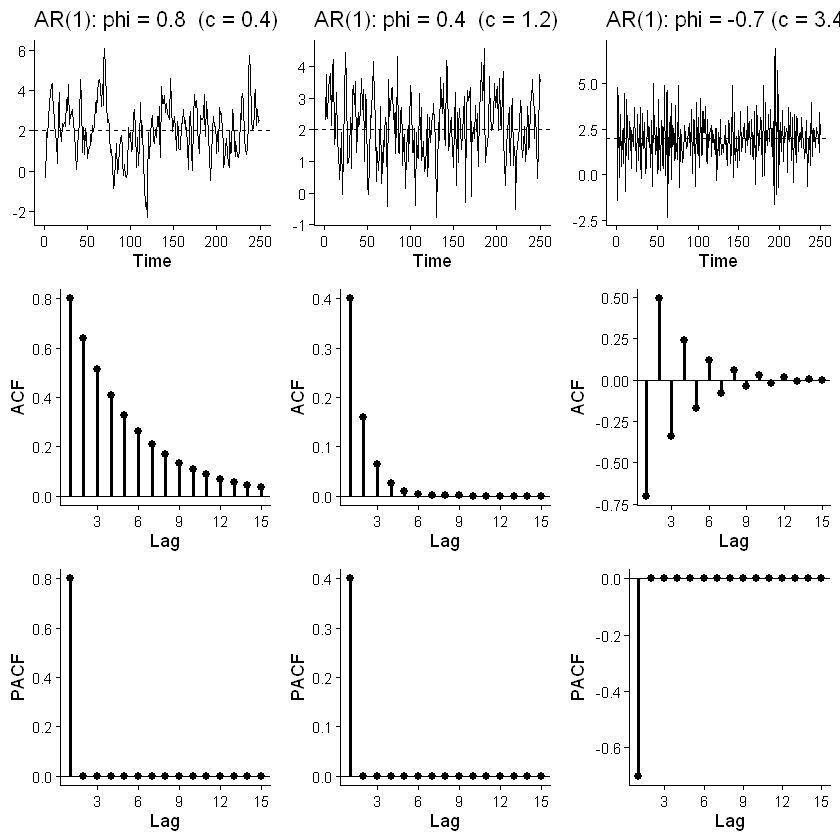

In [2]:
# Three AR(1) processes: realizations, theoretical ACF, theoretical PACF
set.seed(123)

mu <- 2
n  <- 250
phi_a <- 0.8; phi_b <- 0.4; phi_c <- -0.7

y_a <- mu + arima.sim(model = list(ar = phi_a), n = n)
y_b <- mu + arima.sim(model = list(ar = phi_b), n = n)
y_c <- mu + arima.sim(model = list(ar = phi_c), n = n)

g_a <- ts_plot(y_a, mu = mu, title = "AR(1): phi = 0.8  (c = 0.4)")
g_b <- ts_plot(y_b, mu = mu, title = "AR(1): phi = 0.4  (c = 1.2)")
g_c <- ts_plot(y_c, mu = mu, title = "AR(1): phi = -0.7 (c = 3.4)")

grid.arrange(
  g_a, g_b, g_c,
  acf_plot(ar = phi_a), acf_plot(ar = phi_b), acf_plot(ar = phi_c),
  pacf_plot(ar = phi_a), pacf_plot(ar = phi_b), pacf_plot(ar = phi_c),
  ncol = 3
)

**Reading the graphs**

- All three series share the same unconditional mean $\mu=2$.
- $\phi=0.8$ is the most persistent: the series wanders for long stretches and its ACF $\rho_j=0.8^{\,j}$ decays slowly.
- $\phi=0.4$ decays quickly ($\rho_j=0.4^{\,j}$).
- $\phi=-0.7$ produces an **oscillating** ACF, $\rho_j=(-0.7)^{\,j}$, alternating in sign as the series flips above and below the mean from period to period.
- For every AR(1) the theoretical **PACF cuts off after lag 1**: $\phi_{11}=\phi$ and $\phi_{jj}=0$ for $j>1$. This mirror-image of the MA case (ACF cuts off, PACF decays) is what makes the PACF the natural tool for identifying AR order.

### The impulse response as persistence

The IRF $\psi_j=\phi^{\,j}$ makes persistence visual: a bigger $\phi$ means a slower-decaying response and a larger accumulated long-run effect $1/(1-\phi)$.

Long-run effect 1/(1-phi):  phi=0.8 -> 5.00 | phi=0.4 -> 1.67
Half-life ln(0.5)/ln(phi):  phi=0.8 -> 3.11 | phi=0.4 -> 0.76 periods


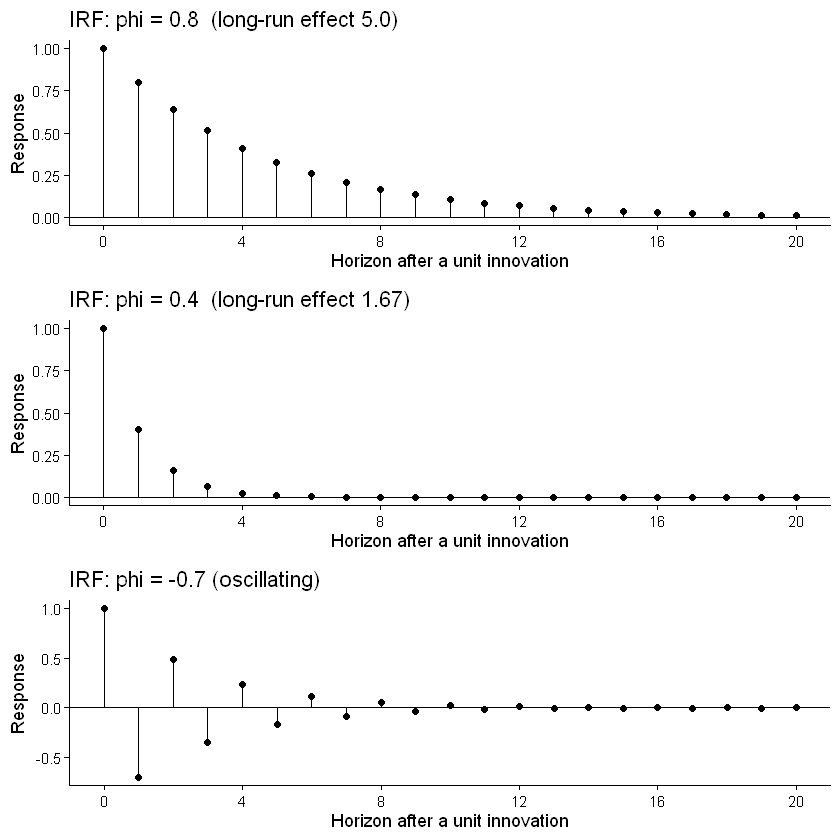

In [3]:
# Impulse responses: persistence rises with phi; phi<0 oscillates
p1 <- irf_plot(ar = 0.8,  h = 20, title = "IRF: phi = 0.8  (long-run effect 5.0)")
p2 <- irf_plot(ar = 0.4,  h = 20, title = "IRF: phi = 0.4  (long-run effect 1.67)")
p3 <- irf_plot(ar = -0.7, h = 20, title = "IRF: phi = -0.7 (oscillating)")
grid.arrange(p1, p2, p3, ncol = 1)

cat(sprintf("Long-run effect 1/(1-phi):  phi=0.8 -> %.2f | phi=0.4 -> %.2f\n",
            1/(1-0.8), 1/(1-0.4)))
cat(sprintf("Half-life ln(0.5)/ln(phi):  phi=0.8 -> %.2f | phi=0.4 -> %.2f periods\n",
            log(0.5)/log(0.8), log(0.5)/log(0.4)))

# 2&nbsp;&nbsp;The AR(2) process

$$
Y_t=c+\phi_1 Y_{t-1}+\phi_2 Y_{t-2}+\varepsilon_t.
$$

## Moments: the Yule–Walker equations

Multiplying the (mean-corrected) equation by $Y_{t-j}$ and taking expectations gives the **Yule–Walker** recursion. The mean is

$$
\mu=\frac{c}{1-\phi_1-\phi_2},
$$

the variance and autocovariances satisfy

$$
\gamma_0=\phi_1\gamma_1+\phi_2\gamma_2+\sigma^2,
\qquad
\gamma_j=\phi_1\gamma_{j-1}+\phi_2\gamma_{j-2}\quad(j\ge1),
$$

and dividing by $\gamma_0$,

$$
\rho_j=\phi_1\rho_{j-1}+\phi_2\rho_{j-2}\qquad(j\ge1).
$$

Solving the first two equations explicitly is worth memorising:

$$
\boxed{\;\rho_1=\frac{\phi_1}{1-\phi_2},
\qquad
\rho_2=\phi_2+\frac{\phi_1^2}{1-\phi_2}=\phi_2+\phi_1\rho_1,\;}
$$

with the variance

$$
\gamma_0=\frac{(1-\phi_2)\,\sigma^2}{(1+\phi_2)\big[(1-\phi_2)^2-\phi_1^2\big]}.
$$

From $\rho_1,\rho_2$ onwards the ACF is generated by the same second-order recursion, so it **decays** (possibly with oscillations) rather than cutting off.

## Stationarity: roots, the triangle, and complex roots

In lag-operator form,

$$
(1-\phi_1 L-\phi_2 L^2)\,Y_t=c+\varepsilon_t,
$$

with characteristic equation (replace $L$ by $z$)

$$
1-\phi_1 z-\phi_2 z^2=0,
\qquad
z_{1,2}=\frac{-\phi_1\pm\sqrt{\phi_1^2+4\phi_2}}{2\phi_2}.
$$

The process is stationary when **both roots lie outside the unit circle**. In terms of the coefficients this is the **stationarity triangle**

$$
\phi_1+\phi_2<1,
\qquad
\phi_2-\phi_1<1,
\qquad
-1<\phi_2<1.
$$

The nature of the dynamics depends on the discriminant $\phi_1^2+4\phi_2$:

- **real distinct roots** ($\phi_1^2+4\phi_2>0$): the ACF/IRF is a sum of two decaying geometric terms — monotone (or sign-alternating) decay;
- **complex-conjugate roots** ($\phi_1^2+4\phi_2<0$): the ACF/IRF is a **damped sinusoid** — the process exhibits *pseudo-cycles*. The stochastic cycle has modulus $r=\sqrt{-\phi_2}$ and period

$$
\text{Period}=\frac{2\pi}{\arccos\!\big(\phi_1/(2\sqrt{-\phi_2})\big)}.
$$

This is the reason AR(2) models are the simplest device for capturing business-cycle-like behaviour.

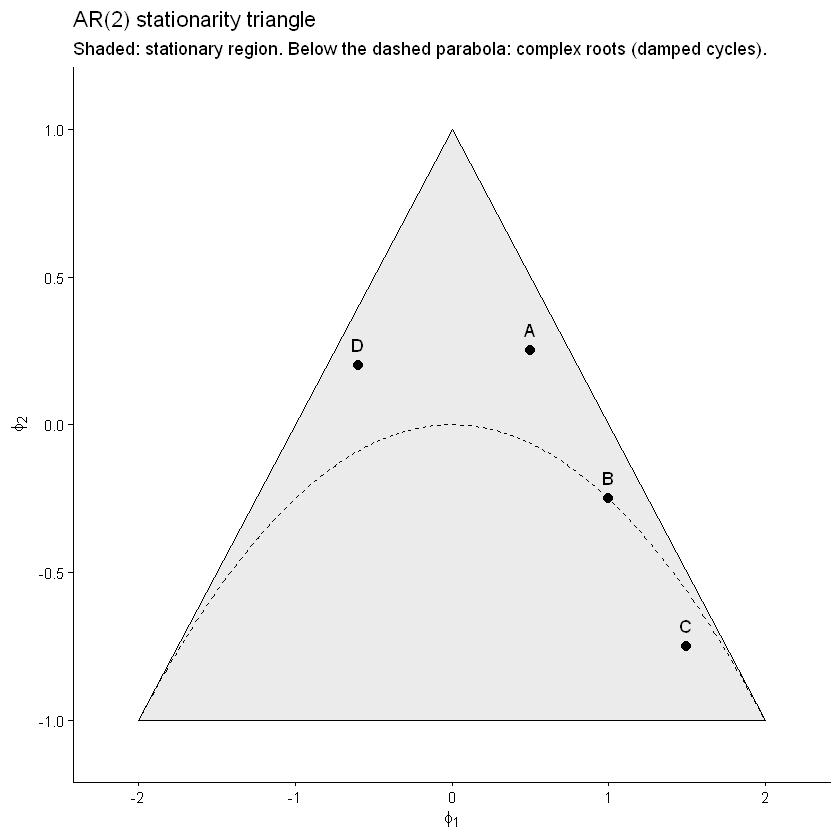

In [4]:
# The AR(2) stationarity triangle, the complex-root parabola, and four models
vertices <- data.frame(phi1 = c(-2, 2, 0), phi2 = c(-1, -1, 1))
grid1    <- seq(-2, 2, length.out = 400)
parab    <- data.frame(phi1 = grid1, phi2 = -grid1^2 / 4)   # phi1^2 + 4 phi2 = 0

models <- data.frame(
  phi1  = c(0.5, 1.0,  1.5, -0.6),
  phi2  = c(0.25, -0.25, -0.75, 0.2),
  label = c("A", "B", "C", "D")
)

ggplot() + theme_classic() +
  geom_polygon(data = vertices, aes(phi1, phi2), fill = "grey92", colour = "black") +
  geom_line(data = parab, aes(phi1, phi2), linetype = "dashed") +
  geom_point(data = models, aes(phi1, phi2), size = 2.5) +
  geom_text(data = models, aes(phi1, phi2, label = label), vjust = -1) +
  coord_cartesian(xlim = c(-2.2, 2.2), ylim = c(-1.1, 1.1)) +
  labs(x = expression(phi[1]), y = expression(phi[2]),
       title = "AR(2) stationarity triangle",
       subtitle = "Shaded: stationary region. Below the dashed parabola: complex roots (damped cycles).")

### Simulation: four AR(2) processes

$$
\text{A: } Y_t=0.5Y_{t-1}+0.25Y_{t-2}+\varepsilon_t,
\qquad
\text{B: } Y_t=1.0Y_{t-1}-0.25Y_{t-2}+\varepsilon_t,
$$

$$
\text{C: } Y_t=1.5Y_{t-1}-0.75Y_{t-2}+\varepsilon_t,
\qquad
\text{D: } Y_t=-0.6Y_{t-1}+0.2Y_{t-2}+\varepsilon_t.
$$

All four sit inside the triangle, so all are stationary. **Predict:** which one shows regular cycles? (Check the discriminant $\phi_1^2+4\phi_2$; model **C** has $1.5^2+4(-0.75)=-0.75<0$.)

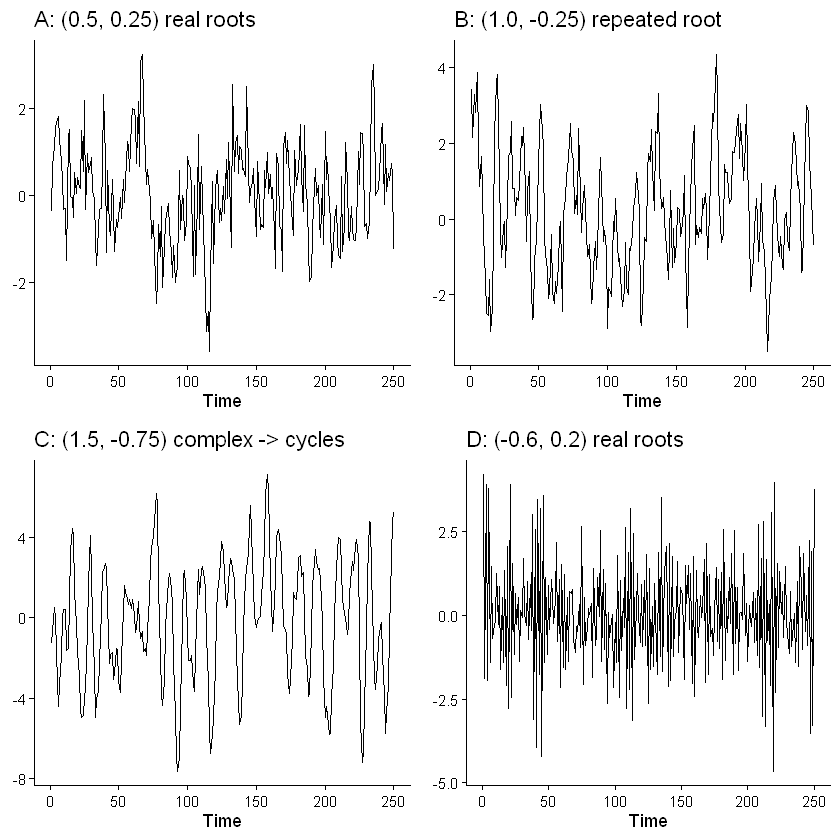

In [5]:
# Four AR(2) realizations
set.seed(123)
n <- 250

ar_A <- c(0.5,  0.25)
ar_B <- c(1.0, -0.25)
ar_C <- c(1.5, -0.75)
ar_D <- c(-0.6, 0.2)

y_A <- arima.sim(model = list(ar = ar_A), n = n)
y_B <- arima.sim(model = list(ar = ar_B), n = n)
y_C <- arima.sim(model = list(ar = ar_C), n = n)
y_D <- arima.sim(model = list(ar = ar_D), n = n)

grid.arrange(
  ts_plot(y_A, title = "A: (0.5, 0.25) real roots"),
  ts_plot(y_B, title = "B: (1.0, -0.25) repeated root"),
  ts_plot(y_C, title = "C: (1.5, -0.75) complex -> cycles"),
  ts_plot(y_D, title = "D: (-0.6, 0.2) real roots"),
  ncol = 2
)

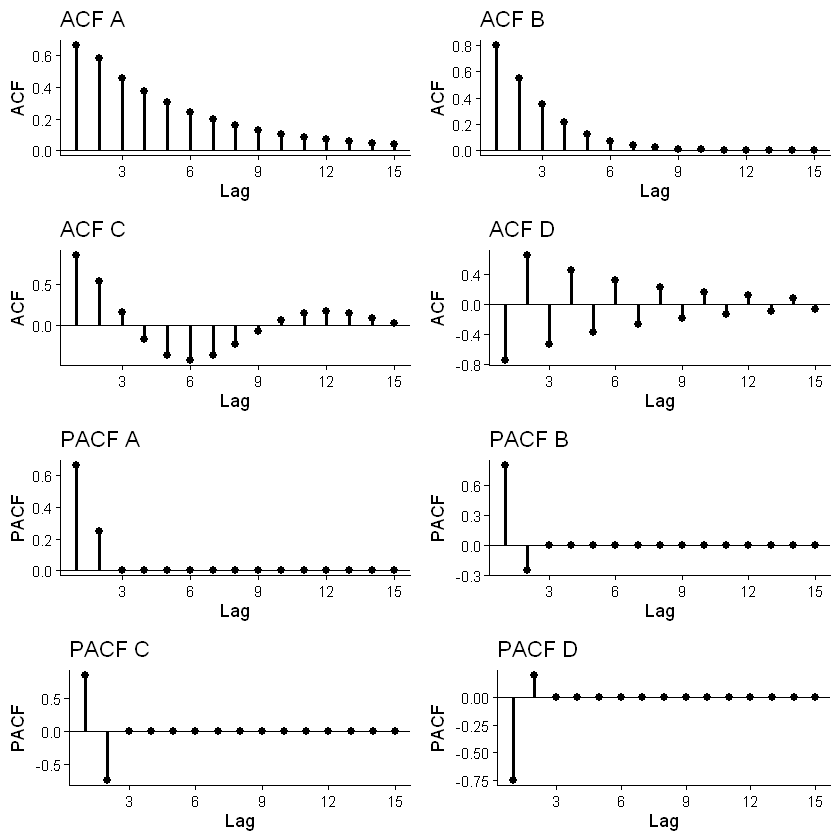

In [6]:
# Theoretical ACF and PACF of the four AR(2) processes
grid.arrange(
  acf_plot(ar = ar_A, title = "ACF A"), acf_plot(ar = ar_B, title = "ACF B"),
  acf_plot(ar = ar_C, title = "ACF C"), acf_plot(ar = ar_D, title = "ACF D"),
  pacf_plot(ar = ar_A, title = "PACF A"), pacf_plot(ar = ar_B, title = "PACF B"),
  pacf_plot(ar = ar_C, title = "PACF C"), pacf_plot(ar = ar_D, title = "PACF D"),
  ncol = 2
)

**Reading the graphs**

- Every ACF **decays** toward zero; the decay pattern (monotone vs oscillatory vs cyclical) is governed by the characteristic roots.
- Model **C** has complex roots and its ACF/series show clear **damped cycles**. Its inverse-root modulus is $\sqrt{0.75}\approx0.87$ and $\cos\theta=1.5/(2\sqrt{0.75})=0.866$, i.e. $\theta=\pi/6$ and a period of $2\pi/\theta=12$ — a cycle roughly every twelve periods.
- In every case the **PACF cuts off after lag 2**: two nonzero partial autocorrelations, then zero. This is the AR(2) signature.

Model C characteristic roots (should be complex, outside unit circle):
[1] 1+0.5773503i 1-0.5773503i
moduli: 1.155 1.155 

Inverse-root modulus r = 0.866, implied cycle period = 12.0 periods


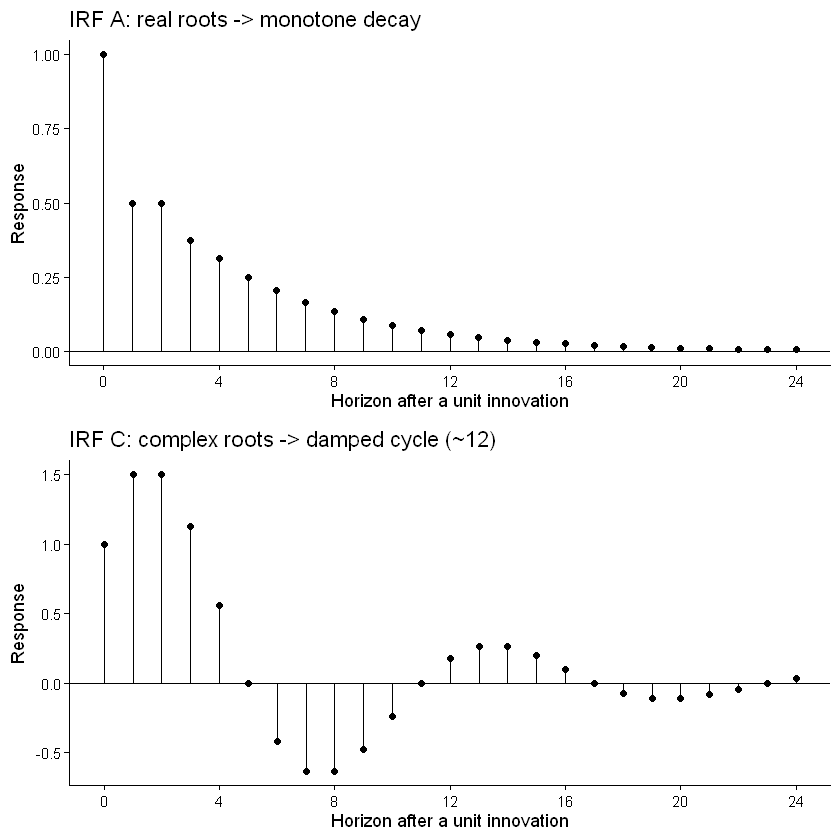

In [7]:
# Confirm the cyclical period of model C from its characteristic roots
r_C <- polyroot(c(1, -ar_C[1], -ar_C[2]))   # 1 - phi1 z - phi2 z^2
cat("Model C characteristic roots (should be complex, outside unit circle):\n")
print(r_C); cat("moduli:", round(Mod(r_C), 3), "\n\n")

# Cycle from the *inverse* roots (eigenvalues of the companion matrix)
lam   <- 1 / r_C
period <- 2 * pi / Mod(Arg(lam[1]))
cat(sprintf("Inverse-root modulus r = %.3f, implied cycle period = %.1f periods\n",
            Mod(lam[1]), period))

# Real vs complex roots also show up in the impulse response
grid.arrange(
  irf_plot(ar = ar_A, h = 24, title = "IRF A: real roots -> monotone decay"),
  irf_plot(ar = ar_C, h = 24, title = "IRF C: complex roots -> damped cycle (~12)"),
  ncol = 1
)

# 3&nbsp;&nbsp;The general AR($p$) process

$$
Y_t=c+\phi_1 Y_{t-1}+\cdots+\phi_p Y_{t-p}+\varepsilon_t
\quad\Longleftrightarrow\quad
\phi(L)\,Y_t=c+\varepsilon_t,
$$

with AR lag polynomial

$$
\phi(z)=1-\phi_1 z-\phi_2 z^2-\cdots-\phi_p z^p.
$$

An AR($p$) is **stable and covariance-stationary** iff all $p$ roots of $\phi(z)=0$ have modulus greater than one (lie outside the unit circle).

### Moments (Yule–Walker)

$$
\mu=\frac{c}{1-\phi_1-\cdots-\phi_p},
$$

$$
\gamma_j=
\begin{cases}
\phi_1\gamma_1+\cdots+\phi_p\gamma_p+\sigma^2, & j=0,\\[4pt]
\phi_1\gamma_{j-1}+\cdots+\phi_p\gamma_{j-p}, & j>0,
\end{cases}
\qquad
\rho_j=\phi_1\rho_{j-1}+\cdots+\phi_p\rho_{j-p}\quad(j>0).
$$

### Wold representation

Factorising $\phi(L)=\prod_{i=1}^{p}(1-\lambda_i L)$ and inverting each factor (valid when every $|\lambda_i|<1$, i.e. every characteristic root is outside the unit circle),

$$
X_t=\psi(L)\varepsilon_t,
\qquad
\psi(L)=\prod_{i=1}^{p}\Big(\sum_{j=0}^{\infty}\lambda_i^{\,j}L^{\,j}\Big),\qquad X_t- Y_t-\mu
$$
 
an MA($\infty$) whose coefficients $\psi_j$ are the impulse response.

## Companion form and the eigenvalue condition

Checking $p$ polynomial roots by hand is awkward; the **companion form** turns the AR($p$) into a first-order vector recursion whose stability is an eigenvalue problem. Stack the last $p$ values,

$$
\mathbf Z_t=F\,\mathbf Z_{t-1}+v_t,
\qquad
\mathbf Z_t=\begin{bmatrix}X_t\\ X_{t-1}\\ \vdots\\ X_{t-p+1}\end{bmatrix},
\quad
F=\begin{bmatrix}
\phi_1 & \phi_2 & \cdots & \phi_{p-1} & \phi_p\\
1 & 0 & \cdots & 0 & 0\\
0 & 1 & \cdots & 0 & 0\\
\vdots & & \ddots & & \vdots\\
0 & 0 & \cdots & 1 & 0
\end{bmatrix},
\quad
v_t=\begin{bmatrix}\varepsilon_t\\0\\\vdots\\0\end{bmatrix}.
$$

The process is stationary iff **all eigenvalues of $F$ lie inside the unit circle**, $|\lambda_i|<1$. The eigenvalues of $F$ are exactly the **reciprocals of the characteristic roots**, so "eigenvalues inside" and "roots outside" are the same statement. This companion/eigenvalue formulation is what carries over directly to VARs and state-space models later in the course.

In [1]:
# Two equivalent stationarity checks for AR(2) model A: (0.5, 0.25)
ar_A <- c(0.5, 0.25)

# (i) roots of 1 - phi1 z - phi2 z^2 : want modulus > 1
roots_A <- polyroot(c(1, -ar_A[1], -ar_A[2]))
cat("Characteristic roots:", round(roots_A, 3), " | moduli:",
    round(Mod(roots_A), 3), "(outside unit circle)\n")

# (ii) eigenvalues of the companion matrix F : want modulus < 1
F_A <- rbind(ar_A, c(1, 0))
eig_A <- eigen(F_A)$values
cat("Companion eigenvalues:", round(eig_A, 3), " | moduli:",
    round(Mod(eig_A), 3), "(inside unit circle)\n")
cat("Reciprocal check 1/roots:", round(1/roots_A, 3), "\n")

roots_plot(roots_A, title = "AR(2) model A: characteristic roots vs unit circle")

Characteristic roots: 1.236+0i -3.236+0i  | moduli: 1.236 3.236 (outside unit circle)
Companion eigenvalues: 0.809 -0.309  | moduli: 0.809 0.309 (inside unit circle)
Reciprocal check 1/roots: 0.809+0i -0.309+0i 


ERROR: Error in roots_plot(roots_A, title = "AR(2) model A: characteristic roots vs unit circle"): could not find function "roots_plot"


# 4&nbsp;&nbsp;The partial autocorrelation function (PACF)

For an AR($p$) the ACF decays and never cleanly signals the order $p$. The **partial autocorrelation function** solves this. The $j$-th partial autocorrelation is the correlation between $Y_t$ and $Y_{t-j}$ **after removing** the linear influence of the intervening lags:

$$
\phi_{jj}=\operatorname{Corr}\big(Y_t,\,Y_{t-j}\mid Y_{t-1},\ldots,Y_{t-j+1}\big).
$$

Operationally, run the sequence of regressions on mean-corrected data $X_t=Y_t-\mu$,

$$
X_t=\phi_{11}X_{t-1}+e_t,
$$
$$
X_t=\phi_{12}X_{t-1}+\phi_{22}X_{t-2}+e_t,
$$
$$
X_t=\phi_{13}X_{t-1}+\phi_{23}X_{t-2}+\phi_{33}X_{t-3}+e_t,\ \ldots
$$

The last coefficient in each regression, $\phi_{jj}$, is the $j$-th PACF value: the *extra* explanatory power of $Y_{t-j}$ once all shorter lags are included.

> **The identification duality.** For an **AR($p$)** the PACF **cuts off after lag $p$** while the ACF decays. For an **MA($q$)** it is the mirror image: the ACF cuts off after lag $q$ while the PACF decays. Reading the two together is the heart of Box–Jenkins identification.

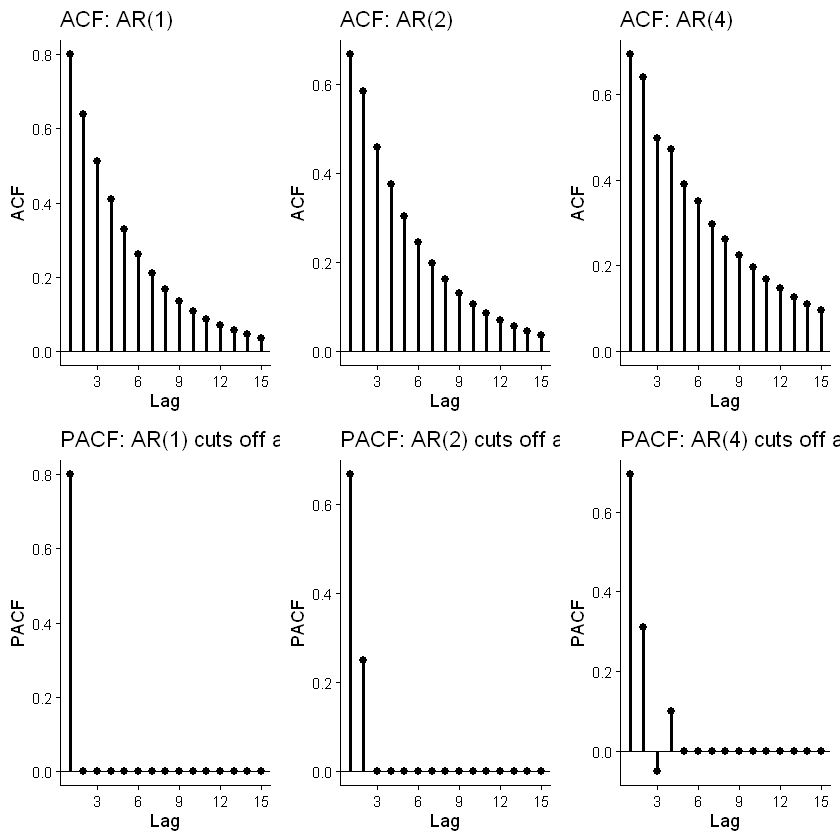

In [10]:
# ACF decays but PACF cuts off at the AR order: AR(1), AR(2), AR(4)
set.seed(123)
n <- 250

ar1 <- 0.8
ar2 <- c(0.5, 0.25)
ar4 <- c(0.5, 0.3, -0.1, 0.1)

grid.arrange(
  acf_plot(ar = ar1, title = "ACF: AR(1)"),
  acf_plot(ar = ar2, title = "ACF: AR(2)"),
  acf_plot(ar = ar4, title = "ACF: AR(4)"),
  pacf_plot(ar = ar1, title = "PACF: AR(1) cuts off at 1"),
  pacf_plot(ar = ar2, title = "PACF: AR(2) cuts off at 2"),
  pacf_plot(ar = ar4, title = "PACF: AR(4) cuts off at 4"),
  ncol = 3
)

### Population versus sample correlogram

Every ACF/PACF above is a **population** quantity computed from known coefficients. In practice we see only one realization and estimate a **sample** ACF/PACF, which fluctuates around the truth inside approximate $\pm 2/\sqrt{T}$ bands (dashed). The identification logic — "PACF cuts off at $p$" — must be read through that sampling noise. (The formal sampling distributions and tests belong to the estimation lecture.)

**Predict:** for a simulated AR(2), roughly how many sample PACF spikes should clearly exceed the bands?

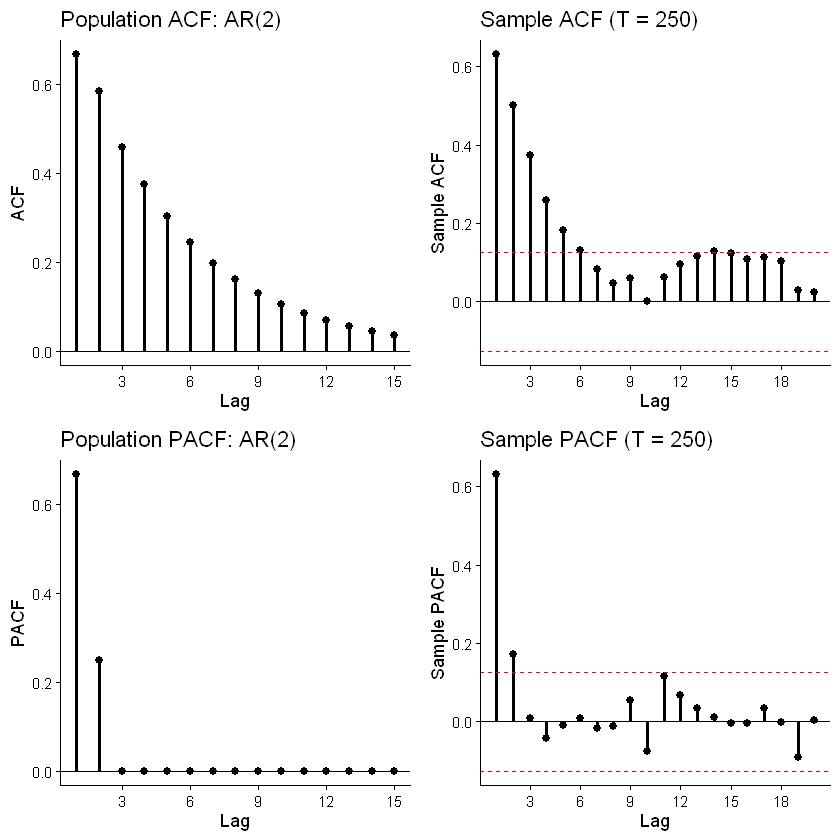

In [11]:
# Theoretical vs sample correlogram for one AR(2) realization
set.seed(2024)
y_ar2 <- arima.sim(model = list(ar = c(0.5, 0.25)), n = 250)

grid.arrange(
  acf_plot(ar = c(0.5, 0.25), title = "Population ACF: AR(2)"),
  sample_acf_plot(y_ar2,       title = "Sample ACF (T = 250)"),
  pacf_plot(ar = c(0.5, 0.25), title = "Population PACF: AR(2)"),
  sample_pacf_plot(y_ar2,      title = "Sample PACF (T = 250)"),
  ncol = 2
)

# 5&nbsp;&nbsp;Invertibility: the dual of stationarity

Just as a stationary AR can be written as an MA($\infty$), an **invertible MA** can be written as an AR($\infty$). Invertibility is the condition that makes the innovation recoverable from current and past *observations* — indispensable for forecasting and for a unique parameterisation (recall the MA(1) $\theta$ vs $1/\theta$ ambiguity from Lecture 5).

For an MA(1),

$$
Y_t-\mu=(1+\beta L)\varepsilon_t
\quad\Longrightarrow\quad
\varepsilon_t=(1+\beta L)^{-1}(Y_t-\mu)=\sum_{j=0}^{\infty}(-\beta)^{\,j}(Y_{t-j}-\mu),
$$

which converges iff $|\beta|<1$, i.e. the root of $1+\beta z=0$ lies outside the unit circle. More generally an MA($q$) is invertible iff every root of

$$
1+\beta_1 z+\cdots+\beta_q z^q=0
$$

lies outside the unit circle.

This is the exact mirror of the AR stationarity condition: **stationarity constrains the AR roots, invertibility constrains the MA roots.**

In [12]:
# Invertibility of an MA(2): Y_t = eps_t + 1.0 eps_{t-1} + 0.7 eps_{t-2}
ma_roots <- polyroot(c(1, 1.0, 0.7))     # 1 + 1.0 z + 0.7 z^2
cat("MA(2) roots:", round(ma_roots, 3), "\n")
cat("moduli     :", round(Mod(ma_roots), 3), " -> all > 1, so invertible\n")

MA(2) roots: -0.714+0.958i -0.714-0.958i 
moduli     : 1.195 1.195  -> all > 1, so invertible


### Two invertible MA(2) processes: ACF cuts off, PACF decays

$$
Y_{1t}=2+\varepsilon_t+1.0\,\varepsilon_{t-1}+0.7\,\varepsilon_{t-2},
\qquad
Y_{2t}=2+\varepsilon_t-1.2\,\varepsilon_{t-1}+0.25\,\varepsilon_{t-2}.
$$

**Predict:** the ACF should cut off after lag 2 for both. The PACF should *decay* (monotone or oscillatory depending on the MA roots) rather than cut off — the reverse of the AR pattern.

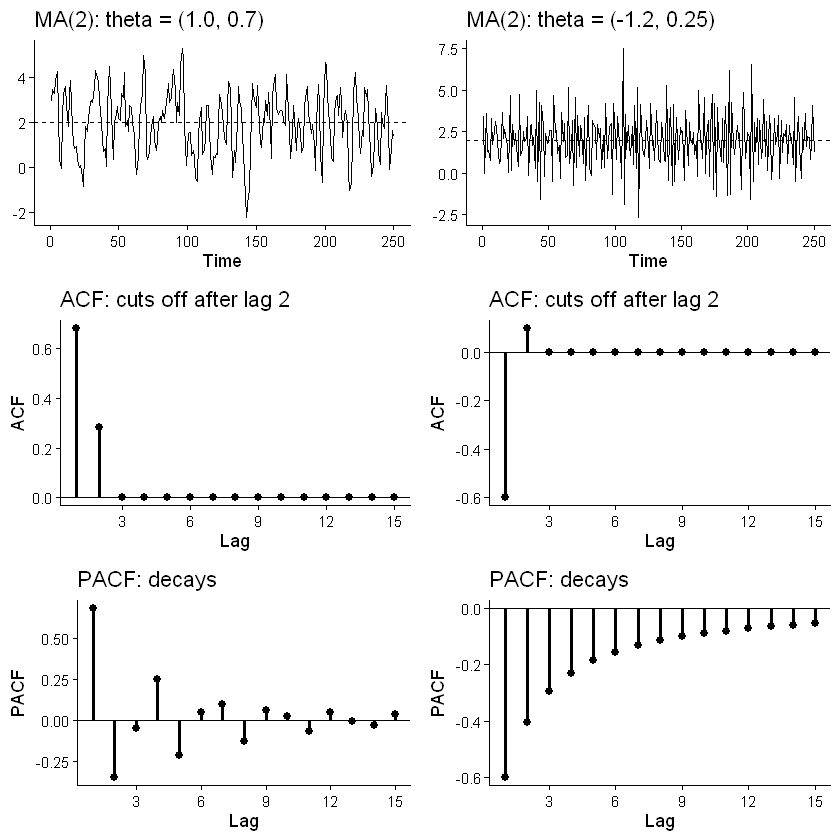

In [13]:
# Two MA(2) processes: realizations, ACF (cuts off at 2), PACF (decays)
set.seed(123)
n <- 250
ma_1 <- c(1.0, 0.7)
ma_2 <- c(-1.2, 0.25)

s1 <- 2 + arima.sim(model = list(ma = ma_1), n = n)
s2 <- 2 + arima.sim(model = list(ma = ma_2), n = n)

grid.arrange(
  ts_plot(s1, mu = 2, title = "MA(2): theta = (1.0, 0.7)"),
  ts_plot(s2, mu = 2, title = "MA(2): theta = (-1.2, 0.25)"),
  acf_plot(ma = ma_1, title = "ACF: cuts off after lag 2"),
  acf_plot(ma = ma_2, title = "ACF: cuts off after lag 2"),
  pacf_plot(ma = ma_1, title = "PACF: decays"),
  pacf_plot(ma = ma_2, title = "PACF: decays"),
  ncol = 2
)

# 6&nbsp;&nbsp;The ARMA($p,q$) process

Combining the two components,

$$
Y_t=c+\phi_1 Y_{t-1}+\cdots+\phi_p Y_{t-p}
+\varepsilon_t+\beta_1\varepsilon_{t-1}+\cdots+\beta_q\varepsilon_{t-q},
$$

or in lag-operator form

$$
\phi(L)\,Y_t=c+\beta(L)\,\varepsilon_t,
\qquad
\phi(L)=1-\phi_1 L-\cdots-\phi_p L^p,
\quad
\beta(L)=1+\beta_1 L+\cdots+\beta_q L^q.
$$

Two separate conditions govern its behaviour:

- **stationarity** depends only on the **AR** polynomial $\phi(L)$ (roots outside the unit circle);
- **invertibility** depends only on the **MA** polynomial $\beta(L)$ (roots outside the unit circle).

When stationary, the Wold representation is $Y_t=\phi(L)^{-1}c+\dfrac{\beta(L)}{\phi(L)}\varepsilon_t$.

## Moments and the ARMA(1,1) example

$$
\mu=\frac{c}{1-\phi_1-\cdots-\phi_p},
\qquad
\gamma_j=\phi_1\gamma_{j-1}+\cdots+\phi_p\gamma_{j-p}\ \ \text{for }j\ge q+1,
$$

so the ACF obeys the pure-AR recursion once past lag $q$. For lags $j\le q$ the MA terms contribute extra covariance. For the ARMA(1,1),

$$
Y_t=c+\phi Y_{t-1}+\varepsilon_t+\beta\varepsilon_{t-1},
$$

$$
\mu=\frac{c}{1-\phi},
\qquad
\gamma_0=\frac{1+2\phi\beta+\beta^2}{1-\phi^2}\,\sigma^2,
\qquad
\gamma_1=\frac{(1+\phi\beta)(\phi+\beta)}{1-\phi^2}\,\sigma^2,
$$

$$
\rho_1=\frac{(1+\phi\beta)(\phi+\beta)}{1+2\phi\beta+\beta^2},
\qquad
\rho_j=\phi\,\rho_{j-1}\ \ (j\ge2).
$$

The ACF decays geometrically at rate $\phi$ after lag 1, but the first-lag value blends both the AR and MA parameters.

### Parameter redundancy (common factors)

ARMA models are only identified if $\phi(L)$ and $\beta(L)$ share **no common root**. If they do, the common factor cancels and the model is over-parameterised. For example,

$$
(1-0.5L)\,Y_t=(1-0.5L)\,\varepsilon_t
\quad\Longrightarrow\quad
Y_t=\varepsilon_t,
$$

an "ARMA(1,1)" that is really white noise. This is why parsimony matters: before trusting an estimated ARMA($p,q$), check that the AR and MA roots are not (nearly) cancelling. Near-common factors show up in practice as unstable estimates and are a standard reason to prefer a smaller model.

### Simulation: an ARMA(2,2)

$$
Y_t=-0.6Y_{t-1}+0.2Y_{t-2}
+\varepsilon_t-1.2\varepsilon_{t-1}+0.25\varepsilon_{t-2}.
$$

The AR coefficients reuse model **D** (stationary) and the MA coefficients reuse the second MA(2) above (invertible), so the process is both stationary and invertible. **Predict:** with $p>0$ and $q>0$, *neither* the ACF nor the PACF should cut off cleanly — both decay.

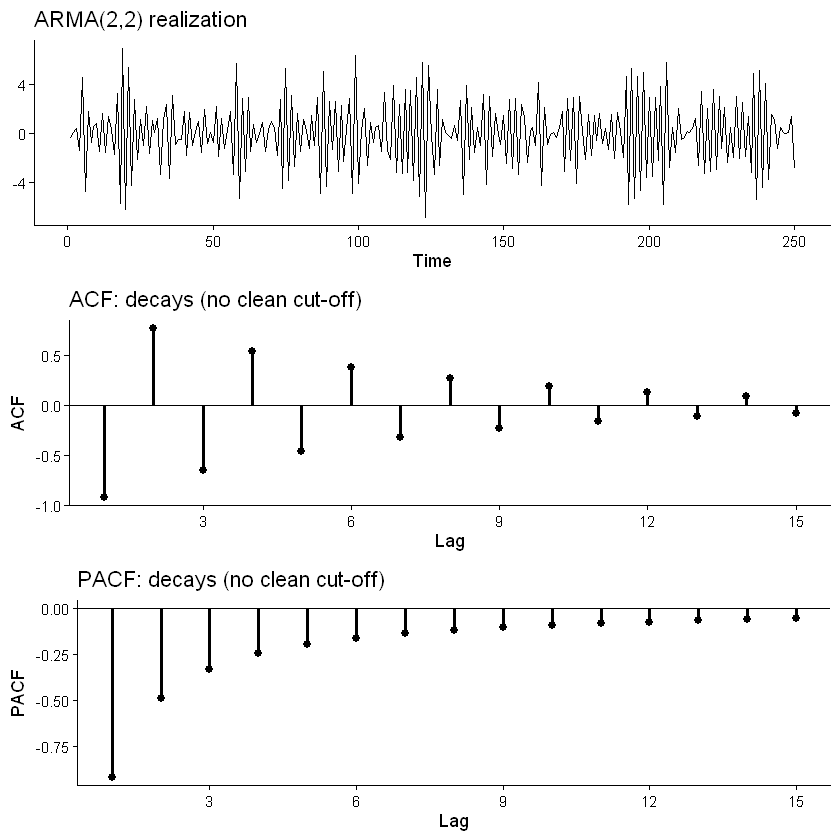

In [14]:
# ARMA(2,2): stationary AR part (D) + invertible MA part
set.seed(123)
ar_arma <- c(-0.6, 0.2)
ma_arma <- c(-1.2, 0.25)

y_arma <- arima.sim(model = list(ar = ar_arma, ma = ma_arma), n = 250)

grid.arrange(
  ts_plot(y_arma, title = "ARMA(2,2) realization"),
  acf_plot(ar = ar_arma, ma = ma_arma, title = "ACF: decays (no clean cut-off)"),
  pacf_plot(ar = ar_arma, ma = ma_arma, title = "PACF: decays (no clean cut-off)"),
  ncol = 1
)

# 7&nbsp;&nbsp;Identifying a model from the ACF and PACF

The ACF and PACF together fingerprint the model class. This table is the practical payoff of the whole lecture.

| Process | ACF | PACF |
|---|---|---|
| **White noise** | zero at all lags $>0$ | zero at all lags $>0$ |
| **AR($p$)** | decays (monotone or oscillatory) | **cuts off after lag $p$** |
| **MA($q$)** | **cuts off after lag $q$** | decays (monotone or oscillatory) |
| **ARMA($p,q$)** | decays after lag $q$ | decays after lag $p$ |

**Sign patterns worth remembering**

- AR(1), $\phi>0$: ACF is positive geometric decay; $\phi<0$: ACF alternates sign. PACF is a single spike $\phi_{11}=\phi$.
- MA(1), $\beta>0$: single positive ACF spike at lag 1; $\beta<0$: single negative spike. PACF decays.
- ARMA(1,1): geometric ACF decay after lag 1 with $\operatorname{sign}(\rho_1)=\operatorname{sign}(\phi+\beta)$; PACF decays after lag 1.

Read together with the caveat from Section 4: with real data these patterns are seen through sampling noise, so identification narrows the field to a few candidate $(p,q)$ rather than pinning down one — the remaining choice is settled by estimation and diagnostics in the next lecture.

## Key takeaways

You should now be able to:

- solve an AR(1) and read persistence off the impulse response $\psi_j=\phi^{\,j}$, the half-life, and the long-run effect $1/(1-\phi)$;
- state stationarity through the characteristic roots (outside the unit circle) and recover the Wold / MA($\infty$) form;
- compute AR(2) moments via Yule–Walker, place a model in the stationarity triangle, and explain how complex roots produce damped cycles of period $2\pi/\arccos\!\big(\phi_1/2\sqrt{-\phi_2}\big)$;
- write an AR($p$) in companion form and check stationarity through the eigenvalues of $F$;
- define the PACF and use the ACF/PACF duality (AR: PACF cuts off; MA: ACF cuts off) to identify order;
- explain invertibility as the MA-side mirror of stationarity;
- describe ARMA($p,q$) moments and ACF/PACF behaviour, and recognise parameter redundancy from common AR/MA roots.

## Exercises

### Exercise 1 — AR(1) moments and persistence
For $Y_t=1+0.6Y_{t-1}+\varepsilon_t$ with $\varepsilon_t\sim WN(0,\,4)$, find $\mu$, $\gamma_0$, $\rho_1$, $\rho_2$, the long-run effect of a unit shock, and the half-life. Sketch the ACF.

### Exercise 2 — Stationarity from roots
For each process, write the characteristic polynomial, find its roots, and decide whether it is stationary:
$$
Y_t=1.2Y_{t-1}-0.32Y_{t-2}+\varepsilon_t,
\qquad
Y_t=0.6Y_{t-1}+0.5Y_{t-2}+\varepsilon_t.
$$

### Exercise 3 — The stationarity triangle
Using the conditions $\phi_1+\phi_2<1$, $\phi_2-\phi_1<1$, $-1<\phi_2<1$, decide which of $(\phi_1,\phi_2)=(0.8,0.1)$, $(1.4,-0.5)$, $(0.3,0.8)$ are stationary. For the stationary ones, which have complex roots?

### Exercise 4 — Cycles from complex roots
For $Y_t=1.5Y_{t-1}-0.75Y_{t-2}+\varepsilon_t$, verify the roots are complex and show the implied cycle period is 12. What happens to the cycle's amplitude over time, and why?

### Exercise 5 — ACF and PACF signatures
Without computing anything, state whether the ACF and the PACF cut off or decay for: (a) MA(2); (b) AR(3); (c) ARMA(1,2); (d) white noise. Which pair of tools identifies each order?

### Exercise 6 — Invertibility
Show that $\beta=0.5$ and $\beta=2$ (with suitable innovation variances) give the same MA(1) ACF. Which is invertible? Write the invertible one as an AR($\infty$).

### Exercise 7 — Parameter redundancy
Show that $(1-0.7L)Y_t=(1-0.7L)\varepsilon_t$ collapses to white noise. Why does this make the ARMA(1,1) parameters unidentified, and how would you spot the problem from estimated AR and MA roots?

### Exercise 8 — Companion form
Write the companion matrix $F$ for $Y_t=0.9Y_{t-1}-0.2Y_{t-2}+\varepsilon_t$, find its eigenvalues, and confirm they are the reciprocals of the characteristic roots and lie inside the unit circle.

## Suggested reading

- Hamilton, J. D. (1994), *Time Series Analysis*, Chapters 1–3 (difference equations, lag operators, stationary ARMA processes and their moments; companion form).
- Brockwell, P. J. and Davis, R. A., *Introduction to Time Series and Forecasting*, chapters on ARMA models, ACF/PACF, and invertibility.
- Enders, W., *Applied Econometric Time Series*, chapter on stationary ARMA models and Box–Jenkins identification.
- Hyndman, R. J. and Athanasopoulos, G., *Forecasting: Principles and Practice*, chapters on autoregressive, moving-average, and ARIMA models for a computational treatment.